In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("UrbanHub - Pollution") \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4,com.amazonaws:aws-java-sdk-bundle:1.12.262") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://minio:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false") \
    .config("spark.sql.session.timeZone", "UTC") \
    .getOrCreate()

print("Spark pret :", spark.version)

Spark pret : 3.5.1


In [2]:
historique = spark.read.option("recursiveFileLookup", "true").json("s3a://bronze/pollution/historique/")

print("Nombre de lignes :", historique.count())
historique.printSchema()
historique.show(5, truncate=False)

Nombre de lignes : 295671
root
 |-- latitude: double (nullable = true)
 |-- location_id: long (nullable = true)
 |-- location_name: string (nullable = true)
 |-- longitude: double (nullable = true)
 |-- pollutant: string (nullable = true)
 |-- sensor_id: long (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- unit: string (nullable = true)
 |-- value: double (nullable = true)
 |-- ville: string (nullable = true)

+-----------------+-----------+---------------+------------------+---------+---------+--------------------+-----+-----+---------+
|latitude         |location_id|location_name  |longitude         |pollutant|sensor_id|timestamp           |unit |value|ville    |
+-----------------+-----------+---------------+------------------+---------+---------+--------------------+-----+-----+---------+
|43.28333999977458|2162727    |VALLEE HUVEAUNE|5.5113839995850205|o3       |7773652  |2026-07-23T12:00:00Z|µg/m³|127.0|Marseille|
|43.28333999977458|2162727    |VALLEE HUVEAUNE|5.5

In [3]:
from pyspark.sql import functions as F

# Combien de mesures par polluant et par unite ?
historique.groupBy("pollutant", "unit").count().orderBy("pollutant").show()

# Valeur minimum et maximum de chaque polluant
historique.groupBy("pollutant").agg(F.min("value"), F.max("value")).show()

+---------+-----+------+
|pollutant| unit| count|
+---------+-----+------+
|       co|µg/m³|  5874|
|      no2|µg/m³|107371|
|       o3|µg/m³| 53566|
|     pm10|µg/m³| 49882|
|     pm25|µg/m³| 78978|
+---------+-----+------+

+---------+----------+----------+
|pollutant|min(value)|max(value)|
+---------+----------+----------+
|       o3|       0.0|     341.0|
|     pm10|       0.2|     666.0|
|      no2|       0.0|     497.0|
|     pm25|       0.0|     655.0|
|       co|       0.0|    2400.0|
+---------+----------+----------+



In [4]:
# Limite maximum plausible PAR polluant (en µg/m³)
limites = {"pm25": 1000, "pm10": 1000, "no2": 1000, "o3": 1000, "co": 20000}
limite_max = F.create_map([F.lit(x) for kv in limites.items() for x in kv])

silver = (historique
    # Regle 1 : texte -> vraie date/heure
    .withColumn("timestamp", F.to_timestamp("timestamp"))
    # Regle 2 : on garde seulement les valeurs plausibles, selon le polluant
    .filter(F.col("value").isNotNull() & F.col("timestamp").isNotNull())
    .filter((F.col("value") >= 0) & (F.col("value") <= limite_max[F.col("pollutant")]))
    # Regle 3 : un seul enregistrement par capteur et par heure
    .dropDuplicates(["sensor_id", "timestamp"])
    # Regle 4 : colonnes utiles (heure de Paris)
    .withColumn("heure_paris", F.from_utc_timestamp("timestamp", "Europe/Paris"))
    .withColumn("date", F.to_date("heure_paris"))
    .withColumn("heure", F.hour("heure_paris"))
    .withColumn("jour_semaine", F.date_format("heure_paris", "E"))
    .withColumn("mois", F.month("heure_paris"))
    .drop("heure_paris")
)

print("Avant :", historique.count(), "lignes")
print("Apres :", silver.count(), "lignes")
silver.show(5)

Avant : 295671 lignes
Apres : 295665 lignes
+------------------+-----------+-----------------+-----------------+---------+---------+-------------------+-----+-----+-----+----------+-----+------------+----+
|          latitude|location_id|    location_name|        longitude|pollutant|sensor_id|          timestamp| unit|value|ville|      date|heure|jour_semaine|mois|
+------------------+-----------+-----------------+-----------------+---------+---------+-------------------+-----+-----+-----+----------+-----+------------+----+
|45.774819999808635|       2680|Lyon Périphérique|4.898572000411539|      no2|     5587|2026-07-23 14:00:00|µg/m³| 45.2| Lyon|2026-07-23|   16|         Thu|   7|
|45.774819999808635|       2680|Lyon Périphérique|4.898572000411539|      no2|     5587|2026-07-23 21:00:00|µg/m³| 41.6| Lyon|2026-07-23|   23|         Thu|   7|
|45.774819999808635|       2680|Lyon Périphérique|4.898572000411539|      no2|     5587|2026-07-23 23:00:00|µg/m³| 32.4| Lyon|2026-07-24|    1|   

In [5]:
(silver.write
    .mode("overwrite")
    .partitionBy("ville")
    .parquet("s3a://silver/pollution/historique/"))

print("Silver enregistre !")

Silver enregistre !


In [6]:
silver.groupBy("ville", "pollutant").agg(F.avg("value")).orderBy("ville").show(30)

+---------+---------+------------------+
|    ville|pollutant|        avg(value)|
+---------+---------+------------------+
| Bordeaux|     pm25| 6.452177657480331|
| Bordeaux|     pm10|16.578320566555856|
| Bordeaux|       o3|  66.5920660948537|
| Bordeaux|      no2|  11.6524299896281|
|     Lyon|     pm10| 17.48833021028525|
|     Lyon|      no2|19.200201748486926|
|     Lyon|     pm25| 5.866399949596776|
|     Lyon|       co|  185.575476558475|
|     Lyon|       o3|  67.8954224642065|
|Marseille|       o3| 69.98105758783055|
|Marseille|      no2|  24.6583300198807|
|Marseille|     pm10| 19.71203703703703|
|Marseille|     pm25| 9.194531735081068|
|Marseille|       co|205.02384576357179|
|    Paris|     pm10|18.226144469838626|
|    Paris|     pm25| 6.259136314737928|
|    Paris|       o3| 61.88910482414647|
|    Paris|      no2|20.721348650120316|
|    Paris|       co|165.58511722731907|
| Toulouse|     pm25| 7.757228471325829|
| Toulouse|       o3| 73.80778097982706|
| Toulouse|     

In [7]:
silver.filter(F.col("pollutant") == "no2").groupBy("heure").agg(F.avg("value")).orderBy("heure").show(24)

+-----+------------------+
|heure|        avg(value)|
+-----+------------------+
|    0| 23.41042154566746|
|    1|20.709463574607643|
|    2|18.307195767195765|
|    3|15.799765313306736|
|    4|14.452663656884871|
|    5|14.622126677852355|
|    6|16.950032916392367|
|    7|21.408616583676118|
|    8|25.420159586951417|
|    9| 27.04951789157917|
|   10|24.257477631018315|
|   11| 21.24599495065412|
|   12|19.579350348027848|
|   13|  16.7252152793111|
|   14|14.350588491717527|
|   15|13.564510601841933|
|   16|13.474136442141626|
|   17|14.263755847627532|
|   18|15.565236148955488|
|   19|17.214591611479033|
|   20|20.142709677419354|
|   21|23.190990587180625|
|   22|25.242377592473822|
|   23|24.907745381704885|
+-----+------------------+



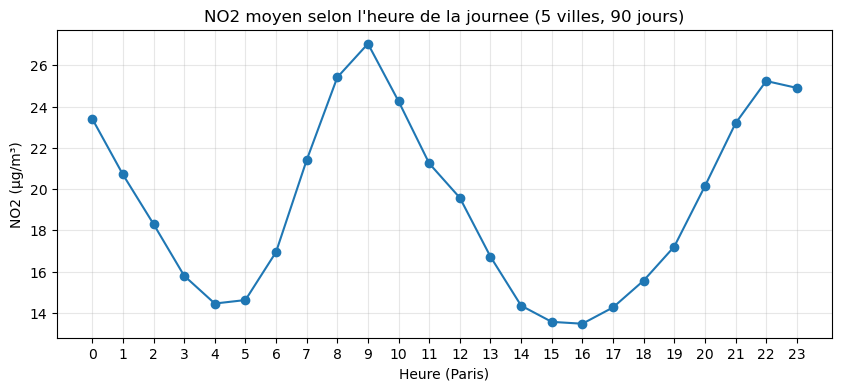

In [8]:
import matplotlib.pyplot as plt

# 1. Meme calcul que toi, mais on garde le resultat au lieu de l'afficher
profil = (silver.filter(F.col("pollutant") == "no2")
          .groupBy("heure").agg(F.avg("value").alias("no2_moyen"))
          .orderBy("heure")
          .toPandas())

# 2. Le graphique
plt.figure(figsize=(10, 4))
plt.plot(profil["heure"], profil["no2_moyen"], marker="o")
plt.title("NO2 moyen selon l'heure de la journee (5 villes, 90 jours)")
plt.xlabel("Heure (Paris)")
plt.ylabel("NO2 (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

In [9]:
seuils_oms = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100, "co": 4000}
seuil = F.create_map([F.lit(x) for kv in seuils_oms.items() for x in kv])

dominant = (silver.groupBy("ville", "pollutant")
    .agg(F.avg("value").alias("moyenne"))
    .withColumn("seuil_oms", seuil[F.col("pollutant")])
    .withColumn("indice", F.round(F.col("moyenne") / F.col("seuil_oms"), 2))
    .orderBy("ville", F.desc("indice")))

dominant.show(30)

+---------+---------+------------------+---------+------+
|    ville|pollutant|           moyenne|seuil_oms|indice|
+---------+---------+------------------+---------+------+
| Bordeaux|       o3|  66.5920660948537|      100|  0.67|
| Bordeaux|      no2|  11.6524299896281|       25|  0.47|
| Bordeaux|     pm25| 6.452177657480331|       15|  0.43|
| Bordeaux|     pm10|16.578320566555856|       45|  0.37|
|     Lyon|      no2|19.200201748486926|       25|  0.77|
|     Lyon|       o3|  67.8954224642065|      100|  0.68|
|     Lyon|     pm10| 17.48833021028525|       45|  0.39|
|     Lyon|     pm25| 5.866399949596776|       15|  0.39|
|     Lyon|       co|  185.575476558475|     4000|  0.05|
|Marseille|      no2|  24.6583300198807|       25|  0.99|
|Marseille|       o3| 69.98105758783055|      100|   0.7|
|Marseille|     pm25| 9.194531735081068|       15|  0.61|
|Marseille|     pm10| 19.71203703703703|       45|  0.44|
|Marseille|       co|205.02384576357179|     4000|  0.05|
|    Paris|   

In [10]:
silver.filter(F.col("pollutant") == "no2").groupBy("ville", "location_name").agg(F.avg("value").alias("no2_moyen")).orderBy(F.desc("no2_moyen")).show(10)

+---------+--------------------+------------------+
|    ville|       location_name|         no2_moyen|
+---------+--------------------+------------------+
|    Paris|Auto A1 -Saint-Denis|50.242768914050416|
|Marseille|MARSEILLE PLOMBIE...| 46.68632862644417|
|     Lyon|   Lyon Périphérique|43.580240722166494|
|    Paris|    RN20 - MONTLHERY| 40.46175213675213|
|    Paris|Bld peripherique Est| 34.62472670484123|
|     Lyon|     A7 SUD LYONNAIS|33.023398890569844|
| Toulouse|Toulouse Port de ...|31.184830230010952|
| Toulouse|     Toulouse Arcole|29.999754901960785|
|    Paris|  Place Victor Basch|28.826082365364314|
|    Paris|  Quai des Celestins|26.584391259105097|
+---------+--------------------+------------------+
only showing top 10 rows



In [11]:
# 1. Moyenne par jour, par ville et par polluant
journalier = (silver.groupBy("ville", "pollutant", "date")
    .agg(F.avg("value").alias("moyenne_jour"))
    .withColumn("seuil_oms", seuil[F.col("pollutant")]))

# 2. On garde seulement les jours au-dessus du seuil
episodes = journalier.filter(F.col("moyenne_jour") > F.col("seuil_oms"))

# 3. On compte les jours de depassement
episodes.groupBy("ville", "pollutant").count().orderBy(F.desc("count")).show()

# Bonus : les 10 pires journees
episodes.orderBy(F.desc(F.col("moyenne_jour") / F.col("seuil_oms"))).show(10)

+---------+---------+-----+
|    ville|pollutant|count|
+---------+---------+-----+
|Marseille|      no2|   40|
|    Paris|      no2|   24|
|     Lyon|      no2|   16|
| Toulouse|      no2|   11|
|Marseille|     pm25|   10|
| Bordeaux|     pm25|    7|
| Toulouse|       o3|    6|
|     Lyon|       o3|    6|
| Toulouse|     pm25|    5|
|    Paris|     pm25|    4|
|     Lyon|     pm25|    4|
|Marseille|       o3|    3|
| Bordeaux|     pm10|    3|
| Bordeaux|       o3|    3|
|Marseille|     pm10|    2|
| Bordeaux|      no2|    2|
|     Lyon|     pm10|    1|
|    Paris|       o3|    1|
+---------+---------+-----+

+--------+---------+----------+------------------+---------+
|   ville|pollutant|      date|      moyenne_jour|seuil_oms|
+--------+---------+----------+------------------+---------+
|Bordeaux|     pm25|2026-07-26| 91.01071428571429|       15|
|Bordeaux|     pm25|2026-07-25| 57.38333333333333|       15|
|   Paris|      no2|2026-10-15| 61.66333333333333|       25|
|Bordeaux|     pm

In [12]:
# Q1 : zones les plus polluees en NO2
zones = (silver.filter(F.col("pollutant") == "no2")
    .groupBy("ville", "location_name", "latitude", "longitude")
    .agg(F.avg("value").alias("no2_moyen")))

# Q2 : profil horaire de chaque polluant, par ville
profil = (silver.groupBy("ville", "pollutant", "heure")
    .agg(F.avg("value").alias("moyenne")))

# Q3 : polluant dominant -> deja calcule : "dominant"
# Q4 : moyennes par jour -> deja calcule : "journalier"

tables_gold = {
    "zones_no2": zones,
    "profil_horaire": profil,
    "polluant_dominant": dominant,
    "journalier": journalier,
}

for nom, table in tables_gold.items():
    table.write.mode("overwrite").parquet(f"s3a://gold/pollution/{nom}/")
    print("Enregistre :", nom)

Enregistre : zones_no2
Enregistre : profil_horaire
Enregistre : polluant_dominant
Enregistre : journalier


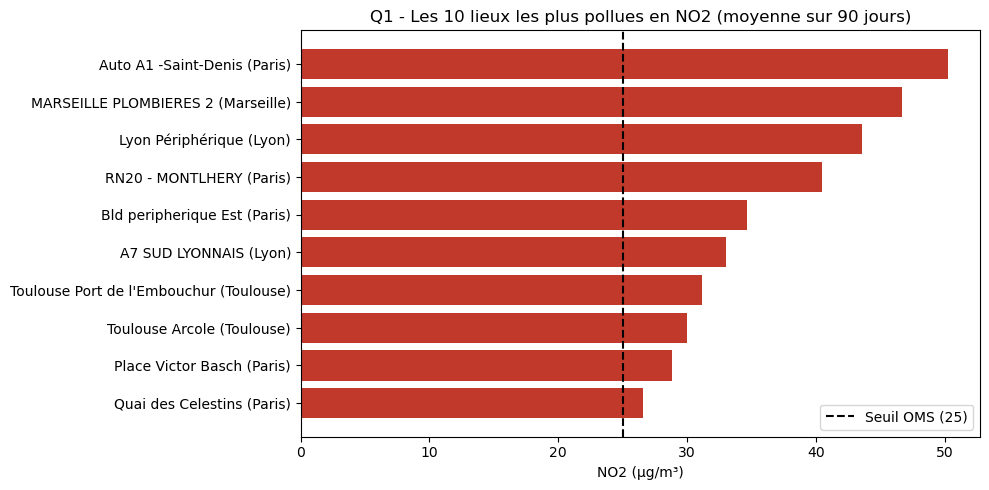

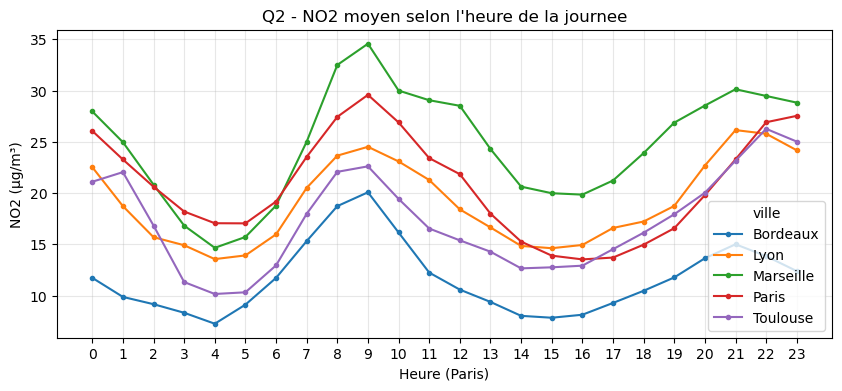

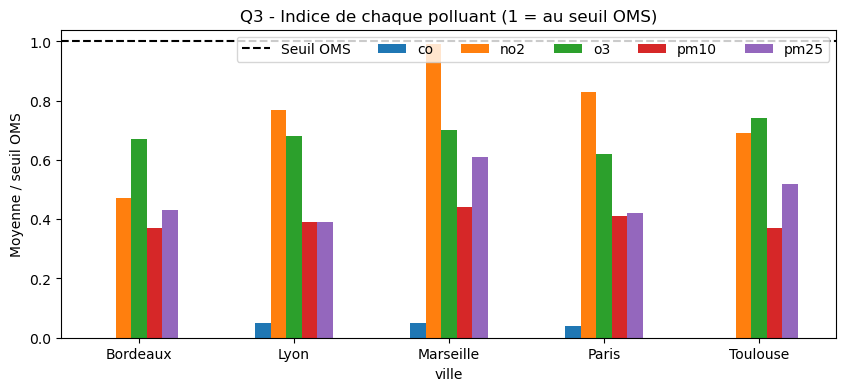

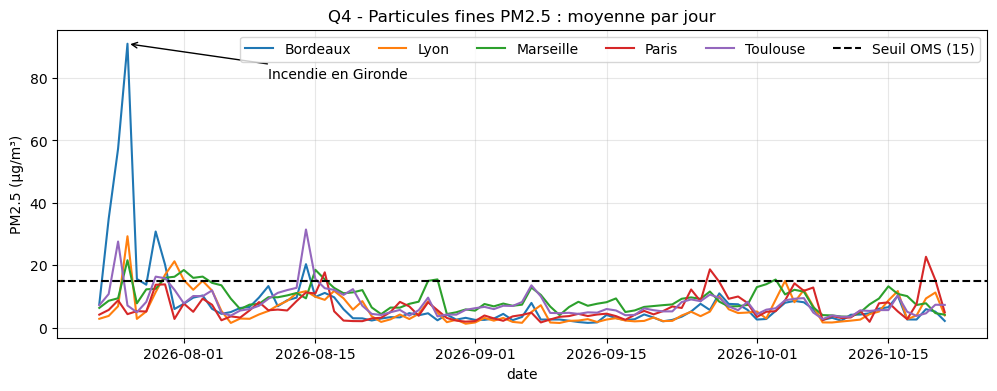

4 graphiques enregistres dans data/figures


In [13]:
import os, datetime
DOSSIER = "/home/jovyan/work/data/figures"
os.makedirs(DOSSIER, exist_ok=True)

# ---------- Q1 : les 10 zones les plus polluees en NO2
z = zones.orderBy(F.desc("no2_moyen")).limit(10).toPandas()
z["lieu"] = z["location_name"].str.slice(0, 28) + " (" + z["ville"] + ")"
plt.figure(figsize=(10, 5))
plt.barh(z["lieu"][::-1], z["no2_moyen"][::-1], color="#c0392b")
plt.axvline(25, ls="--", color="black", label="Seuil OMS (25)")
plt.title("Q1 - Les 10 lieux les plus pollues en NO2 (moyenne sur 90 jours)")
plt.xlabel("NO2 (µg/m³)"); plt.legend(); plt.tight_layout()
plt.savefig(f"{DOSSIER}/pollution_q1_zones.png", dpi=120); plt.show()

# ---------- Q2 : variation dans la journee, par ville
p = (profil.filter(F.col("pollutant") == "no2").toPandas()
     .pivot(index="heure", columns="ville", values="moyenne"))
p.plot(figsize=(10, 4), marker="o", ms=3)
plt.title("Q2 - NO2 moyen selon l'heure de la journee")
plt.xlabel("Heure (Paris)"); plt.ylabel("NO2 (µg/m³)"); plt.xticks(range(24)); plt.grid(alpha=0.3)
plt.savefig(f"{DOSSIER}/pollution_q2_profil_horaire.png", dpi=120, bbox_inches="tight"); plt.show()

# ---------- Q3 : polluant dominant (indice = moyenne / seuil OMS)
d = dominant.toPandas().pivot(index="ville", columns="pollutant", values="indice")
d.plot(kind="bar", figsize=(10, 4))
plt.axhline(1, ls="--", color="black", label="Seuil OMS")
plt.title("Q3 - Indice de chaque polluant (1 = au seuil OMS)")
plt.ylabel("Moyenne / seuil OMS"); plt.xticks(rotation=0); plt.legend(ncol=6)
plt.savefig(f"{DOSSIER}/pollution_q3_dominant.png", dpi=120, bbox_inches="tight"); plt.show()

# ---------- Q4 : episodes de pollution (particules fines PM2.5 jour par jour)
j = (journalier.filter(F.col("pollutant") == "pm25").toPandas()
     .pivot(index="date", columns="ville", values="moyenne_jour").sort_index())
j.plot(figsize=(12, 4))
plt.axhline(15, ls="--", color="black", label="Seuil OMS (15)")
plt.annotate("Incendie en Gironde", xy=(datetime.date(2026, 7, 26), 91),
             xytext=(datetime.date(2026, 8, 10), 80), arrowprops=dict(arrowstyle="->"))
plt.title("Q4 - Particules fines PM2.5 : moyenne par jour")
plt.ylabel("PM2.5 (µg/m³)"); plt.legend(ncol=6); plt.grid(alpha=0.3)
plt.savefig(f"{DOSSIER}/pollution_q4_episodes.png", dpi=120, bbox_inches="tight"); plt.show()

print("4 graphiques enregistres dans data/figures")